# 02 - Key findings

**Client question:** are our promotions actually increasing sales, in which stores and situations, and which should we keep, change or stop?

Three charts, each written as **insight -> so what**. Every comparison is made on **Mon-Fri only** (promotions never run at weekends, so including weekends would
flatter the promo effect) and **each store is compared with itself** (its promo days vs its own non-promo days), so a store's size or type cannot distort the result.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

CLEAN, DOCS = Path("../data/clean"), Path("../docs")
FIG = DOCS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CLEAN / "sales_clean.csv", parse_dates=["Date"])
print(df.shape, "| promo share:", round(df.Promo.mean(), 3))
print("promo rows on Sat/Sun:", ((df.DayOfWeek >= 6) & (df.Promo == 1)).sum())  # 0 -> weekends must be excluded

(38037, 22) | promo share: 0.442
promo rows on Sat/Sun: 0


## Prepare: one uplift number per store

In [2]:
wk = df[df.DayOfWeek <= 5]  # Mon-Fri: the only days where both promo and non-promo exist

by_store = wk.groupby(["Store", "Promo"]).Sales.mean().unstack()  # columns: 0 = no promo, 1 = promo
by_store["uplift_pct"] = (by_store[1] / by_store[0] - 1) * 100
meta = df.groupby("Store").agg(StoreType=("StoreType", "first"), CompetitionDistance=("CompetitionDistance", "first"))
by_store = by_store.join(meta)

mean_sales = wk.groupby("Promo").Sales.mean()
pooled_uplift = (mean_sales[1] / mean_sales[0] - 1) * 100
store_mean_uplift = by_store.uplift_pct.mean()
per_day = wk.assign(spend=wk.Sales / wk.Customers).groupby("Promo")[["Customers", "spend"]].mean()

print(f"avg daily sales  no promo {mean_sales[0]:,.0f}  |  promo {mean_sales[1]:,.0f}  |  pooled uplift {pooled_uplift:+.1f}%")
print(f"per-store uplift: mean {store_mean_uplift:+.1f}%  median {by_store.uplift_pct.median():+.1f}%  "
      f"min {by_store.uplift_pct.min():+.1f}%  max {by_store.uplift_pct.max():+.1f}%  | stores with uplift > 0: {(by_store.uplift_pct > 0).sum()}/50")
print("\ncustomers and spend per customer:\n", per_day.round(2))

avg daily sales  no promo 5,987  |  promo 8,242  |  pooled uplift +37.7%
per-store uplift: mean +39.5%  median +36.2%  min +9.3%  max +93.5%  | stores with uplift > 0: 50/50

customers and spend per customer:
        Customers  spend
Promo                  
0         726.65   8.76
1         864.50  10.07


## Chart style

In [3]:
INK, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3de"
BLUE, GREY, BLUE_LIGHT = "#2a78d6", "#a9a8a1", "#a9c8ef"  # blue = promo / uplift, grey = baseline

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10.5, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

## Chart 1 - Do promotions increase sales at all?

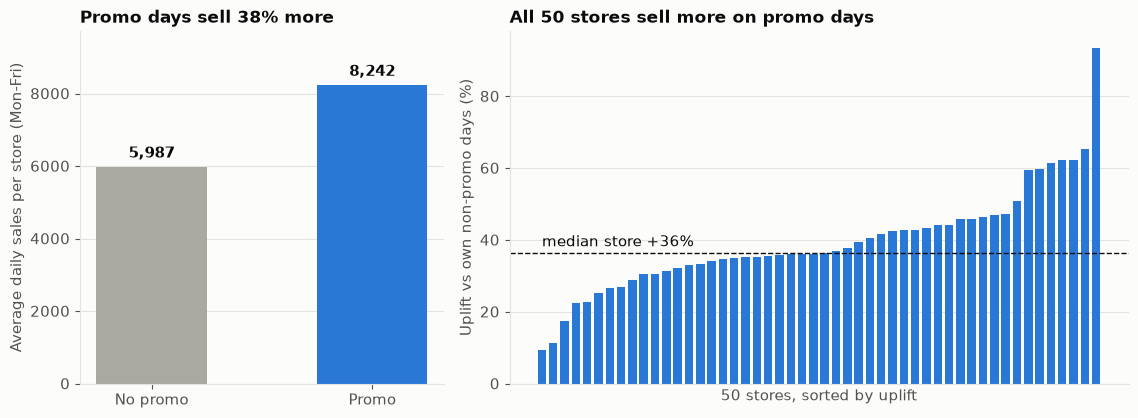

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.7]})

# left: average daily sales, promo vs no promo
bars = ax1.bar(["No promo", "Promo"], [mean_sales[0], mean_sales[1]], color=[GREY, BLUE], width=0.5)
ax1.bar_label(bars, labels=[f"{v:,.0f}" for v in mean_sales], padding=4, color=INK, fontweight="bold")
ax1.set_ylim(0, mean_sales.max() * 1.18)
ax1.set_ylabel("Average daily sales per store (Mon-Fri)")
ax1.set_title(f"Promo days sell {pooled_uplift:.0f}% more")

# right: every store's own uplift, sorted
u = by_store.uplift_pct.sort_values().reset_index(drop=True)
ax2.bar(range(len(u)), u, color=BLUE, width=0.75)
ax2.axhline(by_store.uplift_pct.median(), color=INK, linestyle="--", linewidth=1)
ax2.text(0, by_store.uplift_pct.median() + 2, f"median store {by_store.uplift_pct.median():+.0f}%", ha="left", color=INK)
ax2.set_xlabel("50 stores, sorted by uplift")
ax2.set_xticks([])
ax2.set_ylabel("Uplift vs own non-promo days (%)")
ax2.set_title(f"All {(by_store.uplift_pct > 0).sum()} stores sell more on promo days")

fig.tight_layout()
fig.savefig(FIG / "01_promo_vs_no_promo.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** On Mon-Fri, a store sells about **38% more** on a promo day (5,987 -> 8,242 average daily sales). The lift is not driven by a few stores: **all 50 stores** sell more
on promo days, the weakest by +9%. It comes from both more customers (+19%) and a bigger spend per customer (+15%).

**So what:** Promotions clearly work on average, so the useful question is not "do they work?" but **"where do they pay back?"** Stopping promotions across the board would
cost sales; the decision is about targeting and redesign, not removal.

## Chart 2 - Which store types respond best?

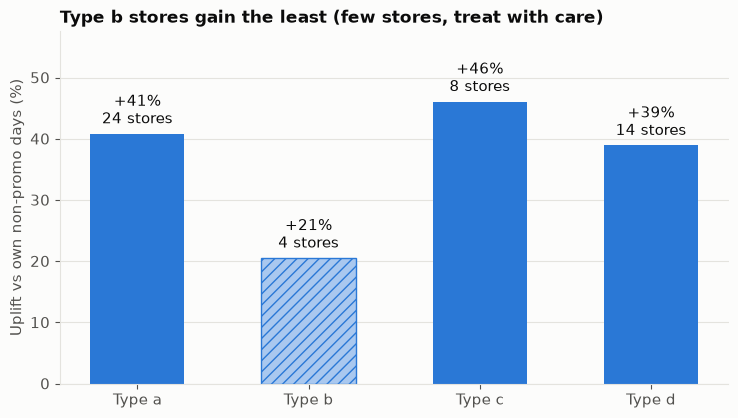

           mean  count
StoreType             
a          40.8     24
b          20.5      4
c          46.1      8
d          38.9     14


In [5]:
order = ["a", "b", "c", "d"]
g = by_store.groupby("StoreType").uplift_pct.agg(["mean", "count"]).loc[order]

fig, ax = plt.subplots(figsize=(7.5, 4.3))
colors = [BLUE_LIGHT if n < 5 else BLUE for n in g["count"]]  # lighter = too few stores to be confident
bars = ax.bar([f"Type {t}" for t in order], g["mean"], color=colors, width=0.55)
for t, b in zip(order, bars):
    if g.loc[t, "count"] < 5:
        b.set_hatch("///"); b.set_edgecolor(BLUE)
ax.bar_label(bars, labels=[f"+{m:.0f}%\n{int(n)} stores" for m, n in zip(g["mean"], g["count"])], padding=4, color=INK)
ax.set_ylim(0, g["mean"].max() * 1.25)
ax.set_ylabel("Uplift vs own non-promo days (%)")
ax.set_title("Type b stores gain the least (few stores, treat with care)")
fig.tight_layout()
fig.savefig(FIG / "02_uplift_by_store_type.png", dpi=150, bbox_inches="tight")
plt.show()
print(g.round(1))

**Insight:** Types a, c and d gain about **39-46%**. Type **b** gains only about **+21%**, roughly half as much. Type b has just 4 stores in this sample (17 in the full chain), so this
is a signal to check, not a proven fact.

**So what:** Type b is the first candidate to **redesign** rather than repeat as is: same promotion, much weaker response. Before acting, confirm on all 17 type-b stores and weigh
the lift against what the promotion costs. One possible reason (a hypothesis, not tested here) is that type-b stores already sell more on normal days, leaving less room to grow.

## Chart 3 - Does competition nearby change how well a promotion works?

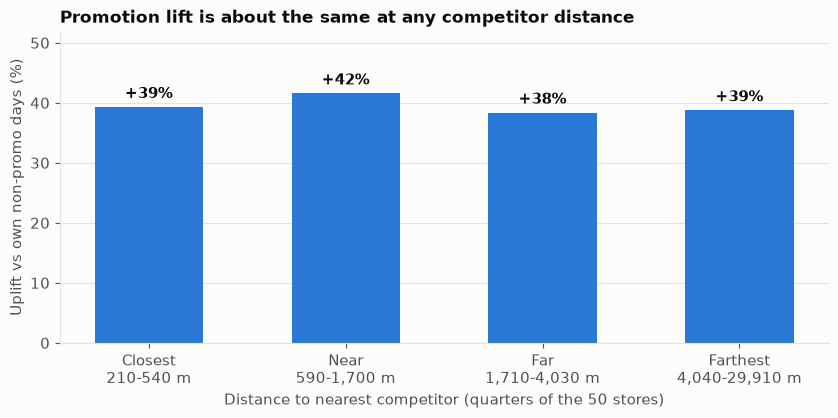

           uplift   n    dmin     dmax
dist_band                             
Closest      39.3  13   210.0    540.0
Near         41.6  12   590.0   1700.0
Far          38.4  12  1710.0   4030.0
Farthest     38.8  13  4040.0  29910.0
rank correlation (distance vs uplift): 0.0


In [6]:
by_store["dist_band"] = pd.qcut(by_store.CompetitionDistance, 4, labels=["Closest", "Near", "Far", "Farthest"])
d = by_store.groupby("dist_band", observed=True).agg(
    uplift=("uplift_pct", "mean"), n=("uplift_pct", "count"),
    dmin=("CompetitionDistance", "min"), dmax=("CompetitionDistance", "max"))
corr = round(by_store.CompetitionDistance.corr(by_store.uplift_pct, method="spearman"), 2) + 0.0  # + 0.0 avoids printing -0.00

fig, ax = plt.subplots(figsize=(8.5, 4.3))
labels = [f"{b}\n{lo:,.0f}-{hi:,.0f} m" for b, lo, hi in zip(d.index, d.dmin, d.dmax)]
bars = ax.bar(labels, d.uplift, color=BLUE, width=0.55)
ax.bar_label(bars, labels=[f"+{v:.0f}%" for v in d.uplift], padding=4, color=INK, fontweight="bold")
ax.set_ylim(0, d.uplift.max() * 1.25)
ax.set_ylabel("Uplift vs own non-promo days (%)")
ax.set_xlabel("Distance to nearest competitor (quarters of the 50 stores)")
ax.set_title("Promotion lift is about the same at any competitor distance")
fig.tight_layout()
fig.savefig(FIG / "03_uplift_by_competition.png", dpi=150, bbox_inches="tight")
plt.show()
print(d.round(1)); print("rank correlation (distance vs uplift):", round(corr, 2))

**Insight:** Promotion lift is **about +38-42% in every distance band**, and the correlation between competitor distance and lift is essentially zero. Stores with a competitor
200 m away respond the same as stores with one 10 km away.

**So what:** Do not target or boost promotions by competition proximity: in this sample it makes no difference. This is a useful "no" finding, and it stops effort being spent
on the wrong lever.

## Caveats (say these out loud)
- **Correlation, not proof of cause.** Promotions were not randomly assigned. If managers ran promos on days they already expected to be busy, part of the lift is not caused by the promo.
  The model stage tries to control for this with store, weekday, month and holidays.
- **No cost data.** All results are about sales, not profit. A +38% sales lift can still lose money if the discount is deep.
- **50-store sample.** Store-type results for type b rest on 4 stores. Re-run on the full 1,115 stores before any real decision.
- **Store-level averages are unweighted:** a small store counts as much as a large one.

## Save the findings for the docs folder

In [7]:
t = g["mean"]
lines = [
    "# Key findings",
    "",
    "Generated by `notebooks/02_key_findings.ipynb`. Sample: 50 stores, Mon-Fri only (promotions never run at weekends). "
    "Every uplift compares a store's promo days with the **same store's** non-promo days.",
    "",
    "## 1. Promotions increase sales, in every store",
    f"- Average daily sales: {mean_sales[0]:,.0f} without promo vs {mean_sales[1]:,.0f} with promo, **{pooled_uplift:+.0f}%**.",
    f"- All {(by_store.uplift_pct > 0).sum()} of 50 stores sell more on promo days; the weakest gains {by_store.uplift_pct.min():+.0f}%, the median store {by_store.uplift_pct.median():+.0f}%.",
    f"- The lift comes from more customers ({per_day.Customers[0]:,.0f} -> {per_day.Customers[1]:,.0f}, {(per_day.Customers[1] / per_day.Customers[0] - 1) * 100:+.0f}%) "
    f"and higher spend per customer ({per_day.spend[0]:.2f} -> {per_day.spend[1]:.2f}, {(per_day.spend[1] / per_day.spend[0] - 1) * 100:+.0f}%).",
    "- **So what:** stopping promotions everywhere would cost sales. The decision is where they pay back, not whether they work.",
    "",
    "## 2. Store type b responds least",
    f"- Uplift by store type: a {t['a']:+.0f}%, b {t['b']:+.0f}%, c {t['c']:+.0f}%, d {t['d']:+.0f}%.",
    f"- Type b has only {int(g.loc['b', 'count'])} stores in the sample, so treat this as a signal to verify on all 17 type-b stores.",
    "- **So what:** type b is the first candidate to redesign or cut back, once promotion cost is known.",
    "",
    "## 3. Competitor distance does not change the promotion effect",
    "- Uplift by distance quarter: " + ", ".join(f"{b.lower()} {v:+.0f}%" for b, v in d.uplift.items()) + f"; rank correlation {corr:.2f}.",
    "- **So what:** do not target promotions by how close a competitor is; it makes no measurable difference in this sample.",
    "",
    "## Caveats",
    "- Promotions were not randomly assigned, so this is association, not proven cause; the model stage controls for store, weekday, month and holidays.",
    "- No promotion cost data, so results are sales lift, not profit.",
    "- 50-store sample; re-run on the full chain before any real decision.",
    "- Store-level averages are unweighted (a small store counts as much as a large one).",
]
(DOCS / "key_findings.md").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

# Key findings

Generated by `notebooks/02_key_findings.ipynb`. Sample: 50 stores, Mon-Fri only (promotions never run at weekends). Every uplift compares a store's promo days with the **same store's** non-promo days.

## 1. Promotions increase sales, in every store
- Average daily sales: 5,987 without promo vs 8,242 with promo, **+38%**.
- All 50 of 50 stores sell more on promo days; the weakest gains +9%, the median store +36%.
- The lift comes from more customers (727 -> 864, +19%) and higher spend per customer (8.76 -> 10.07, +15%).
- **So what:** stopping promotions everywhere would cost sales. The decision is where they pay back, not whether they work.

## 2. Store type b responds least
- Uplift by store type: a +41%, b +21%, c +46%, d +39%.
- Type b has only 4 stores in the sample, so treat this as a signal to verify on all 17 type-b stores.
- **So what:** type b is the first candidate to redesign or cut back, once promotion cost is known.

## 3. Competitor distance does not chan